# CloudLens: does filling cloud-covered pixels help land-cover classification?

**AI61201 Visual Computing with AI/ML** · P. Sai Dharanidhar Ram (24AI10004) and Ruthvik Devarakonda (24AI10023) · Mentor: Prof. Somdyuti Paul

This notebook is our demo for the project. We did not retrain anything here. It loads the trained weights we saved, runs inference on the EuroSAT test split, and checks the numbers in our report.

What is covered:
- Table I (accuracy by cloud coverage, 3 seeds)
- Table II (opacity sweep)
- Table III (RICE real clouds, stored results)
- Tables IV to VI (metric validity and harmful flips, live with the saved classifier)
- The failure taxonomy (manual labels and water-class share)
- Table VII (transfer learning)


**How to run (Colab):** The Google Drive file ID of `cloudlens_assets.zip` is already configured in `ASSETS_GDRIVE_ID` in Section 0. Simply select *Runtime → Run all* to execute the notebook. If the automatic download fails, follow the fallback instructions under **Required assets**. A GPU runtime is recommended for faster execution, but the notebook also supports CPU execution.


**Required assets:** This notebook requires `cloudlens_assets.zip`, containing pretrained model checkpoints, sample evaluation data, and stored experimental results. The notebook automatically downloads the ZIP from the provided Google Drive link. If the automatic download fails, one can:

1. Download `cloudlens_assets.zip`, which is submitted separately alongside the Colab notebook link on Moodle.
2. Run the notebook and upload the ZIP when prompted by the configuration cell.
3. The notebook will automatically validate and extract the ZIP and locate the required assets.

In [20]:
# lpips (perceptual metric) and scikit-image (SSIM) are not always installed on Colab
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lpips", "scikit-image"], check=False)

import os, glob, zipfile, time, warnings
import shutil
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from PIL import Image
from scipy.ndimage import gaussian_filter, distance_transform_edt
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import cv2
from IPython.display import display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, "| torch", torch.__version__)


device: cuda | torch 2.14.1+cu130


## 0. Configuration and assets

In [21]:

# ------------------------------- CONFIG -------------------------------
ASSETS_GDRIVE_ID = "13w8ELUKSMXNHJdt99O8h09e-9Nkg4Cuc"

N_LIVE    = 4050 if dev == "cuda" else 1000
N_BOOT    = 200
N_OPACITY = 500
# ----------------------------------------------------------------------

# Find an already extracted assets folder
def find_base():
    for root in ["cloudlens_assets", ".", "/content"]:
        for p in glob.glob(
            os.path.join(root, "**", "resnet18_clean.pth"),
            recursive=True
        ):
            d = Path(p).parent.parent
            if (d / "data" / "splits" / "test.csv").exists():
                return d.resolve()
    return None


# Check whether ZIP is valid and not corrupted
def valid_zip(path):
    try:
        with zipfile.ZipFile(path, "r") as z:
            return z.testzip() is None
    except Exception:
        return False


# Ask user to upload the ZIP manually
def manual_upload(reason):
    print("\nAutomatic asset download was unsuccessful.")
    print("Reason:", reason)
    print("\nPlease upload cloudlens_assets.zip manually.")

    from google.colab import files
    uploaded = files.upload()

    zip_files = [
        f for f in uploaded
        if f.lower().endswith(".zip")
    ]

    if not zip_files:
        raise RuntimeError(
            "No ZIP uploaded. Please upload cloudlens_assets.zip."
        )

    # Prefer the expected filename
    selected = next(
        (f for f in zip_files if Path(f).name == "cloudlens_assets.zip"),
        zip_files[0]
    )

    ZIP_PATH = "cloudlens_assets.zip"

    if os.path.abspath(selected) != os.path.abspath(ZIP_PATH):
        shutil.copy2(selected, ZIP_PATH)

    if not valid_zip(ZIP_PATH):
        os.remove(ZIP_PATH)
        raise RuntimeError(
            "Uploaded ZIP is corrupted. Please upload a valid cloudlens_assets.zip."
        )

    print("Manual ZIP upload successful.")
    return ZIP_PATH


# First check whether assets are already extracted
BASE = find_base()

if BASE is None:

    ZIP_PATH = "cloudlens_assets.zip"

    # Remove an existing corrupted ZIP
    if os.path.exists(ZIP_PATH) and not valid_zip(ZIP_PATH):
        print("Existing ZIP is corrupted. Removing it...")
        os.remove(ZIP_PATH)

    # Attempt Google Drive download if no valid local ZIP exists
    if not os.path.exists(ZIP_PATH):

        try:
            if ASSETS_GDRIVE_ID == "PUT_DRIVE_FILE_ID_HERE":
                raise RuntimeError("Google Drive ID not configured.")

            try:
                import gdown
            except ImportError:
                import subprocess
                import sys

                subprocess.run(
                    [sys.executable, "-m", "pip", "install", "-q", "gdown"],
                    check=True
                )
                import gdown

            print("Downloading cloudlens_assets.zip from Google Drive...")

            result = gdown.download(
                id=ASSETS_GDRIVE_ID,
                output=ZIP_PATH,
                quiet=False
            )

            if not result or not os.path.exists(ZIP_PATH):
                raise RuntimeError("Google Drive download failed.")

            if not valid_zip(ZIP_PATH):
                raise RuntimeError("Downloaded ZIP is corrupted or invalid.")

            print("Google Drive download successful.")

        except Exception as e:

            # Remove incomplete or invalid download
            if os.path.exists(ZIP_PATH):
                os.remove(ZIP_PATH)

            # Manual upload fallback
            manual_upload(str(e))

    # Extract the valid ZIP
    if not valid_zip(ZIP_PATH):
        raise RuntimeError("Assets ZIP is invalid.")

    print("\nExtracting cloudlens_assets.zip...")

    # Remove incomplete extraction from an earlier attempt
    if os.path.isdir("cloudlens_assets"):
        shutil.rmtree("cloudlens_assets")

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall("cloudlens_assets")

    BASE = find_base()

# Verify expected assets structure
assert BASE is not None, (
    "Assets not found. Please ensure cloudlens_assets.zip contains "
    "models/, results/ and data/splits/test.csv."
)

RES = BASE / "results"

print("\nAssets successfully loaded:", BASE)
print("Available models:")
print(sorted(p.name for p in (BASE / "models").glob("*.pth")))


# Helper: find a results CSV by name anywhere in results/
def read_csv(name, avoid=None):
    hits = [
        p for p in RES.rglob(name)
        if not (avoid and avoid in str(p))
    ]
    return pd.read_csv(hits[0]) if hits else None


# Collect report vs notebook comparison values
SUMMARY = []



Assets successfully loaded: /content/cloudlens_assets
Available models:
['resnet18_clean.pth', 'resnet18_fill_aware.pth', 'resnet18_mask_aware.pth', 'unet_inpaint.pth', 'unet_transfer_unet_imagenet_lr0.0001_seed0.pth', 'unet_transfer_unet_imagenet_seed0.pth', 'unet_transfer_unet_rand_seed0.pth', 'unet_transfer_unet_sat_seed0.pth']


## 1. Model code (same as used in the experiments)

In [ ]:
# the three cloud-coverage bins used in the report
BINS = {"10-30%": (0.10, 0.30), "30-60%": (0.30, 0.60), "60-80%": (0.60, 0.80)}
CLASSES = ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial',
           'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']

# generates the synthetic cloud masks (multi-scale noise, thresholded to a target coverage)
class CloudSimulator:
    def __init__(self, h=64, w=64):
        self.h, self.w = h, w
    def generate_cloud_mask(self, target_bin=(0.30, 0.60), rng=None):
        rng = rng if rng is not None else np.random.default_rng()
        low, high = target_bin
        cov = rng.uniform(low, high)
        n1 = rng.standard_normal((self.h, self.w)); n2 = rng.standard_normal((self.h, self.w)); n3 = rng.standard_normal((self.h, self.w))
        s1 = gaussian_filter(n1, sigma=rng.uniform(6.0, 12.0))
        s2 = gaussian_filter(n2, sigma=rng.uniform(3.0, 6.0))
        s3 = gaussian_filter(n3, sigma=rng.uniform(1.0, 2.5))
        comb = s1 * 0.6 + s2 * 0.3 + s3 * 0.1
        gx, gy = rng.uniform(-1, 1), rng.uniform(-1, 1)
        xx, yy = np.meshgrid(np.linspace(-1, 1, self.w), np.linspace(-1, 1, self.h))
        comb = comb + 0.3 * (gx * xx + gy * yy)
        thr = np.percentile(comb, 100.0 * (1.0 - cov))
        return (comb >= thr).astype(np.uint8)

# thick cloud: pixels inside the mask become a bright white cloud
def apply_thick(clean, mask, rng):
    clean_f = clean.astype(np.float32); H, W, _ = clean.shape
    base = np.clip(rng.normal(loc=238.0, scale=8.0, size=(H, W, 1)).astype(np.float32), 210.0, 255.0)
    base = np.repeat(base, 3, axis=-1)
    m3 = np.repeat(mask[:, :, np.newaxis], 3, axis=-1)
    return np.clip(clean_f * (1.0 - m3) + base * m3, 0, 255).astype(np.uint8)

# semi-transparent cloud with opacity alpha (used for the opacity sweep)
def apply_opacity(clean, mask, alpha, rng):
    H, W, _ = clean.shape
    base = np.clip(rng.normal(238.0, 8.0, (H, W, 1)), 210, 255).astype(np.float32).repeat(3, -1)
    m = mask[..., None].astype(np.float32); c = clean.astype(np.float32)
    return np.clip(c * (1 - m) + (alpha * base + (1 - alpha) * c) * m, 0, 255).astype(np.uint8)

# zero-masking baseline: cloud pixels set to black
def masked_input(img, mask, v=0):
    o = img.copy(); o[mask == 1] = v; return o

# mean fill baseline: cloud pixels set to the average colour of the clear pixels
def mean_fill(img, mask):
    o = img.copy(); un = mask == 0
    mu = [img[:, :, c][un].mean() for c in range(3)] if un.sum() > 0 else [128.0] * 3
    for c in range(3):
        o[mask == 1, c] = np.uint8(np.clip(mu[c], 0, 255))
    return o

# nearest-neighbour fill: copy the closest clear pixel
def nearest_neighbor_fill(img, mask):
    if mask.sum() == 0: return img.copy()
    if (mask == 0).sum() == 0: return np.zeros_like(img)
    _, idx = distance_transform_edt(mask, return_indices=True)
    o = np.zeros_like(img)
    for c in range(3):
        o[:, :, c] = img[:, :, c][idx[0], idx[1]]
    return o

# Telea inpainting from OpenCV (fast marching)
def telea_inpaint(img, mask, radius=3):
    bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    out = cv2.inpaint(bgr, (mask * 255).astype(np.uint8), inpaintRadius=radius, flags=cv2.INPAINT_TELEA)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

def _dark(img, patch):
    return cv2.erode(img.min(axis=2), np.ones((patch, patch), np.uint8))

# dark channel prior dehazing, written from the He et al. paper
def dehaze_dcp(rgb, patch=7, omega=0.95, t0=0.1, top=0.01):
    I = rgb.astype(np.float32) / 255.0
    dark = _dark(I, patch)
    n = max(1, int(dark.size * top))
    idx = np.argsort(dark.ravel())[-n:]
    px = I.reshape(-1, 3)[idx]
    A = px[px.sum(1).argmax()].clip(0.3, 1.0)
    t = 1.0 - omega * _dark(I / A, patch)
    t = cv2.GaussianBlur(t, (0, 0), 2).clip(t0, 1.0)[..., None]
    J = (I - A) / t + A
    return (J.clip(0, 1) * 255).astype(np.uint8)

def dehaze_dcp_masked(rgb, mask, **kw):
    return np.where(mask[..., None].astype(bool), dehaze_dcp(rgb, **kw), rgb)

class DoubleConv(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                                 nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

# the small U-Net that inpaints the cloud pixels (trained on EuroSAT)
class SmallUNetInpainter(nn.Module):
    def __init__(self, in_channels=4, out_channels=3, base_channels=32):
        super().__init__()
        b = base_channels
        self.inc = DoubleConv(in_channels, b)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(b, b * 2))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(b * 2, b * 4))
        self.bottleneck = nn.Sequential(nn.MaxPool2d(2), DoubleConv(b * 4, b * 8))
        self.up1 = nn.ConvTranspose2d(b * 8, b * 4, 2, 2); self.conv_up1 = DoubleConv(b * 8, b * 4)
        self.up2 = nn.ConvTranspose2d(b * 4, b * 2, 2, 2); self.conv_up2 = DoubleConv(b * 4, b * 2)
        self.up3 = nn.ConvTranspose2d(b * 2, b, 2, 2);     self.conv_up3 = DoubleConv(b * 2, b)
        self.outc = nn.Sequential(nn.Conv2d(b, out_channels, 1), nn.Sigmoid())
    def forward(self, x_masked, mask):
        x1 = self.inc(torch.cat([x_masked, mask], 1)); x2 = self.down1(x1); x3 = self.down2(x2)
        xb = self.bottleneck(x3)
        d1 = self.conv_up1(torch.cat([self.up1(xb), x3], 1))
        d2 = self.conv_up2(torch.cat([self.up2(d1), x2], 1))
        d3 = self.conv_up3(torch.cat([self.up3(d2), x1], 1))
        return x_masked * (1.0 - mask) + self.outc(d3) * mask

def _block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

def _up(x, ref):
    return F.interpolate(x, size=ref.shape[-2:], mode="bilinear", align_corners=False)

# ResNet-18 encoder used in the transfer-learning U-Nets
def _resnet_encoder(in_ch):
    m = torchvision.models.resnet18(weights=None)
    if in_ch != 3:
        m.conv1 = nn.Conv2d(in_ch, 64, kernel_size=7, stride=2, padding=3, bias=False)
    return m

# U-Net with a ResNet-18 encoder (transfer learning experiment)
class ResUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = _resnet_encoder(4)
        self.dec4 = _block(512 + 256, 256); self.dec3 = _block(256 + 128, 128)
        self.dec2 = _block(128 + 64, 64);   self.dec1 = _block(64 + 64, 64)
        self.dec0 = _block(64, 32)
        self.out = nn.Sequential(nn.Conv2d(32, 3, 1), nn.Sigmoid())
    def forward(self, x_masked, mask):
        e = self.enc
        x = torch.cat([x_masked, mask], 1)
        x0 = e.relu(e.bn1(e.conv1(x))); x1 = e.layer1(e.maxpool(x0))
        x2 = e.layer2(x1); x3 = e.layer3(x2); x4 = e.layer4(x3)
        d = self.dec4(torch.cat([_up(x4, x3), x3], 1)); d = self.dec3(torch.cat([_up(d, x2), x2], 1))
        d = self.dec2(torch.cat([_up(d, x1), x1], 1));  d = self.dec1(torch.cat([_up(d, x0), x0], 1))
        return self.out(self.dec0(_up(d, x_masked)))

# ResNet-18 classifier with 10 output classes
def get_classifier():
    m = torchvision.models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 10)
    return m

MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)

def load_sd(p):
    try:
        return torch.load(p, map_location=dev, weights_only=True)
    except TypeError:
        return torch.load(p, map_location=dev)

@torch.no_grad()
# run a classifier on a batch of images and return the predicted labels
def predict(model, imgs, bs=256):
    model.eval(); out = []
    for i in range(0, len(imgs), bs):
        x = torch.from_numpy(imgs[i:i + bs]).to(dev).permute(0, 3, 1, 2).float() / 255.0
        out.append(model((x - MEAN) / STD).argmax(1).cpu().numpy())
    return np.concatenate(out)

@torch.no_grad()
# run the U-Net inpainter on a batch of cloudy images
def net_fill(model, cloudy, masks, bs=256):
    model.eval(); out = []
    for i in range(0, len(cloudy), bs):
        x = torch.from_numpy(cloudy[i:i + bs]).to(dev).permute(0, 3, 1, 2).float() / 255.0
        m = torch.from_numpy(masks[i:i + bs]).to(dev).unsqueeze(1).float()
        out.append((model(x, m).permute(0, 2, 3, 1).cpu().numpy() * 255.0).clip(0, 255).astype(np.uint8))
    return np.concatenate(out)

# create the simulator once and reuse it
sim = CloudSimulator(64, 64)
print("code ready")

code ready


## 2. Load the trained models and the EuroSAT test split (4,050 tiles)

In [ ]:
# load one saved ResNet-18 classifier
def load_clf(name):
    m = get_classifier(); m.load_state_dict(load_sd(BASE / "models" / name)); return m.to(dev).eval()

# the three classifiers: clean, mask-aware and fill-aware
clf = {"clean": load_clf("resnet18_clean.pth"),
       "mask_aware": load_clf("resnet18_mask_aware.pth"),
       "fill_aware": load_clf("resnet18_fill_aware.pth")}
# the inpainting U-Net trained on EuroSAT
unet = SmallUNetInpainter().to(dev); unet.load_state_dict(load_sd(BASE / "models" / "unet_inpaint.pth")); unet.eval()

# the list of test tiles, labels and class names
test_df = pd.read_csv(BASE / "data" / "splits" / "test.csv")
# find where each jpg is stored
index = {p.name: p for p in (BASE / "data").rglob("*.jpg")}
# if some tiles are missing from the zip, download EuroSAT with torchvision
if any(f not in index for f in test_df["filename"]):      # tiles not included in the zip: fetch EuroSAT RGB
    from torchvision.datasets import EuroSAT
    EuroSAT(root="/tmp/eurosat_dl", download=True)
    index.update({p.name: p for p in Path("/tmp/eurosat_dl").rglob("*.jpg")})
assert all(f in index for f in test_df["filename"]), "test images not found in the assets or the EuroSAT download"
# load all 4,050 test tiles into one array
X = np.stack([np.array(Image.open(index[f]).convert("RGB")) for f in test_df["filename"]])
y = test_df["label"].astype(int).values
print("test tiles:", X.shape, "| classes:", len(set(y)))


test tiles: (4050, 64, 64, 3) | classes: 10


## 3. Table I: accuracy by coverage (3 seeds, full 4,050-tile test split)

These numbers are read from the stored outputs of the three training runs (`threeway_seed0/1/2.csv`). Each seed gives mean and SD over the test tiles.

In [ ]:
# the four fill methods (the fill-aware classifier was trained on these)
FILLS = ["mean_fill", "nearest_neighbor", "telea", "unet"]
# the rows of Table I, grouped by classifier
PAPER = [("Fill-aware", "fill_aware", [("Mean fill", "mean_fill"), ("Nearest neighbour", "nearest_neighbor"), ("Telea", "telea"),
                                       ("Scratch U-Net", "unet"), ("Cloudy as-is", "cloudy")]),
         ("Mask-aware", "mask_aware", [("Masked (black fill)", "masked_zero")]),
         ("Clean", "clean", [("Cloudy as-is", "cloudy"), ("Nearest neighbour", "nearest_neighbor"), ("Telea", "telea"),
                             ("Scratch U-Net", "unet"), ("Mean fill", "mean_fill")])]

# helper that builds one table from the CSV rows
def table1(df, sd=True):
    rows = []
    for ctitle, c, items in PAPER:
        for label, inp in items:
            sub = df[(df.classifier == c) & (df.input == inp) & (df.bin != "all")]
            g = sub.groupby("bin").acc
            m, s = g.mean(), g.std(ddof=1)
            cells = []
            for b in BINS:
                if b not in m.index: cells.append("-")
                elif sd: cells.append(f"{m[b]:.3f} ± {s[b]:.3f}")
                else: cells.append(f"{m[b]:.3f}")
            rows.append([ctitle, label] + cells)
    return pd.DataFrame(rows, columns=["classifier", "input"] + list(BINS))

# combine the three seeds into one table
tw = pd.concat([pd.read_csv(f) for f in sorted(RES.glob("threeway_seed*.csv"))], ignore_index=True)
print("seeds:", sorted(int(s) for s in tw.seed.unique()), "| test tiles per seed:", int(tw.n.iloc[0]))
display(Markdown("**Table I. Downstream accuracy (mean ± SD over 3 seeds)**"))
display(table1(tw))

# decision rule from our pre-specified analysis plan: for each seed and bin, best fill minus mask-aware
gaps = []
for seed, g in tw.groupby("seed"):
    for b in BINS:
        best = g[(g.classifier == "fill_aware") & g.input.isin(FILLS) & (g.bin == b)].acc.max()
        mk = g[(g.classifier == "mask_aware") & (g.input == "masked_zero") & (g.bin == b)].acc.iloc[0]
        gaps.append(dict(seed=int(seed), bin=b, best_fill_minus_masked_pts=round(100 * (best - mk), 1)))
gp = pd.DataFrame(gaps).pivot(index="seed", columns="bin", values="best_fill_minus_masked_pts")
display(Markdown("**Decision rule: best fill (fill-aware) minus masked (mask-aware), accuracy points per seed**"))
display(gp)
print("Pre-registered rule met (fill-aware > mask-aware in every seed and bin):", bool((gp.values > 0).all()))

# average over seeds
mean_tab = tw.groupby(["classifier", "input", "bin"]).acc.mean()
# the gap between Telea (fill-aware) and the mask-aware baseline, in points
tel_gap = {b: 100 * (mean_tab[("fill_aware", "telea", b)] - mean_tab[("mask_aware", "masked_zero", b)]) for b in BINS}
print("Telea (fill-aware) minus masked (mask-aware), points:", {b: round(v, 1) for b, v in tel_gap.items()})
SUMMARY += [("Fill-aware Telea minus masked, 10-30%", "+5.2", f"{tel_gap['10-30%']:+.1f}"),
            ("Fill-aware Telea minus masked, 30-60%", "+8.3", f"{tel_gap['30-60%']:+.1f}"),
            ("Fill-aware Telea minus masked, 60-80%", "+13.2", f"{tel_gap['60-80%']:+.1f}"),
            ("Telea vs U-Net at 60-80% (fill-aware)", "0.830 vs 0.826",
             f"{mean_tab[('fill_aware','telea','60-80%')]:.3f} vs {mean_tab[('fill_aware','unet','60-80%')]:.3f}")]

# paired bootstrap on the 200-tile subset (a smaller check)
pc = read_csv("paired_comparison.csv")
t = pc[(pc.condition == "thick") & (pc.fill_method == "telea_inpaint")].copy()
for c in ["diff_fill_minus_masked", "diff_ci_low", "diff_ci_high"]:
    t[c] = (100 * t[c]).round(1)
display(Markdown("**Paired bootstrap, Telea minus mask-aware, 200-tile subset (points)**"))
display(t[["coverage_bin", "diff_fill_minus_masked", "diff_ci_low", "diff_ci_high"]].reset_index(drop=True))


seeds: [0, 1, 2] | test tiles per seed: 4050


**Table I. Downstream accuracy (mean ± SD over 3 seeds)**

,classifier,input,10-30%,30-60%,60-80%
0,Fill-aware,Mean fill,0.935 ± 0.009,0.885 ± 0.010,0.789 ± 0.008
1,Fill-aware,Nearest neighbour,0.943 ± 0.009,0.903 ± 0.011,0.799 ± 0.010
2,Fill-aware,Telea,0.950 ± 0.007,0.916 ± 0.008,0.830 ± 0.015
3,Fill-aware,Scratch U-Net,0.948 ± 0.006,0.914 ± 0.006,0.826 ± 0.007
4,Fill-aware,Cloudy as-is,0.682 ± 0.060,0.348 ± 0.103,0.151 ± 0.056
5,Mask-aware,Masked (black fill),0.898 ± 0.013,0.833 ± 0.016,0.698 ± 0.022
6,Clean,Cloudy as-is,0.730 ± 0.041,0.343 ± 0.032,0.137 ± 0.014
7,Clean,Nearest neighbour,0.946 ± 0.009,0.810 ± 0.021,0.441 ± 0.039
8,Clean,Telea,0.942 ± 0.007,0.715 ± 0.032,0.267 ± 0.003
9,Clean,Scratch U-Net,0.939 ± 0.007,0.689 ± 0.039,0.255 ± 0.019


**Decision rule: best fill (fill-aware) minus masked (mask-aware), accuracy points per seed**

bin,10-30%,30-60%,60-80%
seed,,,
0,5.7,9.3,14.6
1,4.5,7.3,11.7
2,5.4,8.3,14.1


Pre-registered rule met (fill-aware > mask-aware in every seed and bin): True
Telea (fill-aware) minus masked (mask-aware), points: {'10-30%': np.float64(5.2), '30-60%': np.float64(8.3), '60-80%': np.float64(13.2)}


**Paired bootstrap, Telea minus mask-aware, 200-tile subset (points)**

,coverage_bin,diff_fill_minus_masked,diff_ci_low,diff_ci_high
0,10-30%,5.0,0.5,9.5
1,30-60%,8.5,3.5,14.5
2,60-80%,15.5,9.0,22.0


## 4. Live re-evaluation with the saved checkpoints (inference only)

This part really runs the models. It rebuilds the cloud masks with the same seeds as the experiments, applies all the fills, and runs the three classifiers. The saved checkpoints come from one training run, so the numbers differ from the 3-seed means by a few points. The ranking and the decision rule are what should match.

In [ ]:
# pick which test tiles to use (all of them when N_LIVE is 4050)
idxs = np.arange(len(X)) if N_LIVE >= len(X) else np.sort(np.random.default_rng(0).permutation(len(X))[:N_LIVE])
Xs, ys = X[idxs], y[idxs]

# make the cloudy versions of the tiles, using the same random seeds as the experiments
def make_cloudy(bi, brange, ids=idxs):
    ms, cs = [], []
    for idx in ids:
        rng = np.random.default_rng(42 + int(idx) * 10 + bi)   # same cloud seeds as the experiments
        m = sim.generate_cloud_mask(brange, rng=rng)
        ms.append(m); cs.append(apply_thick(X[idx], m, rng))
    return np.stack(cs), np.stack(ms)

# apply every fill method to the same cloudy tiles
def make_inputs(cl, mk):
    return {"cloudy": cl,
            "masked_zero": np.stack([masked_input(c, m, 0) for c, m in zip(cl, mk)]),
            "mean_fill": np.stack([mean_fill(c, m) for c, m in zip(cl, mk)]),
            "nearest_neighbor": np.stack([nearest_neighbor_fill(c, m) for c, m in zip(cl, mk)]),
            "telea": np.stack([telea_inpaint(c, m) for c, m in zip(cl, mk)]),
            "unet": net_fill(unet, cl, mk)}

# start the timer
t0 = time.time(); live, harm = [], []
# predictions on the clean tiles (used as the reference for the harmful flips)
cp = {k: predict(m, Xs) for k, m in clf.items()}
for k in clf:
    live.append(dict(classifier=k, bin="all", input="clean", acc=float((cp[k] == ys).mean())))
# loop over the three coverage bins
for bi, (bn, br) in enumerate(BINS.items()):
    cl, mk = make_cloudy(bi, br)
    for inp, arr in make_inputs(cl, mk).items():
        for k, m_ in clf.items():
            p = predict(m_, arr)
            live.append(dict(classifier=k, bin=bn, input=inp, acc=float((p == ys).mean())))
            if k == "fill_aware" and inp in FILLS:
                # harmful flip: right on the clean tile, wrong after the fill
                harm.append(dict(method=inp, bin=bn, harmful_pct=100 * float(((cp[k] == ys) & (p != ys)).mean())))
live = pd.DataFrame(live); harm = pd.DataFrame(harm)
print(f"{len(idxs)} tiles, {time.time() - t0:.0f}s")
print("clean-tile accuracy:", live[live.input == "clean"].set_index("classifier").acc.round(4).to_dict())
display(Markdown("**Table I (live, saved checkpoints)**")); display(table1(live, sd=False))
lg = {}
for b in BINS:
    best = live[(live.classifier == "fill_aware") & live.input.isin(FILLS) & (live.bin == b)].acc.max()
    mk_ = live[(live.classifier == "mask_aware") & (live.input == "masked_zero") & (live.bin == b)].acc.iloc[0]
    lg[b] = round(100 * (best - mk_), 1)
print("best fill (fill-aware) minus masked (mask-aware), points:", lg, "| rule holds:", all(v > 0 for v in lg.values()))
display(Markdown("**Harmful-flip rate (%), fill-aware classifier (live)**"))
display(harm.pivot(index="method", columns="bin", values="harmful_pct").round(1).reindex(["telea", "unet", "nearest_neighbor", "mean_fill"]))

4050 tiles, 100s
clean-tile accuracy: {'clean': 0.9506, 'mask_aware': 0.9612, 'fill_aware': 0.9635}


**Table I (live, saved checkpoints)**

,classifier,input,10-30%,30-60%,60-80%
0,Fill-aware,Mean fill,0.945,0.899,0.807
1,Fill-aware,Nearest neighbour,0.958,0.915,0.836
2,Fill-aware,Telea,0.959,0.927,0.856
3,Fill-aware,Scratch U-Net,0.955,0.923,0.851
4,Fill-aware,Cloudy as-is,0.602,0.346,0.163
5,Mask-aware,Masked (black fill),0.906,0.831,0.697
6,Clean,Cloudy as-is,0.707,0.414,0.161
7,Clean,Nearest neighbour,0.927,0.756,0.397
8,Clean,Telea,0.915,0.573,0.235
9,Clean,Scratch U-Net,0.908,0.556,0.223


best fill (fill-aware) minus masked (mask-aware), points: {'10-30%': np.float64(5.4), '30-60%': np.float64(9.6), '60-80%': np.float64(16.0)} | rule holds: True


**Harmful-flip rate (%), fill-aware classifier (live)**

bin,10-30%,30-60%,60-80%
method,,,
telea,1.3,4.7,12.1
unet,1.8,5.1,12.7
nearest_neighbor,1.6,6.1,14.1
mean_fill,2.9,7.6,17.0


## 5. Metric validity and harmful flips (Tables IV, V and VI)

This section runs live. For every test tile (or the subset in `N_LIVE`) and every coverage bin, we make the cloud with the same seed as the experiments, apply the four fills, and compute:
- PSNR and SSIM inside the cloud mask,
- SSIM and LPIPS on the whole tile,
- whether the **fill-aware classifier** gets the tile right on the clean image and wrong after the fill (a harmful flip).

One thing to know: the report's per-tile file was made by `metric_validity_full.py`, which trains its own fill-aware model. We use the **saved** fill-aware checkpoint instead, so the numbers can differ from the report by a little. The stored report numbers are printed below the live ones for comparison.


In [ ]:
import lpips
from skimage.metrics import structural_similarity

# ---- live metric pass (same definitions as metric_validity_full.py) ----

# LPIPS network: AlexNet features with the learned linear layers
lp_net = lpips.LPIPS(net="alex").to(dev).eval()

def psnr_in_mask(clear, filled, masks):
    # PSNR computed only on the pixels that were covered by cloud
    out = np.full(len(clear), np.nan)
    for i, (a, b, m) in enumerate(zip(clear, filled, masks)):
        mm = m.astype(bool)
        if mm.any():
            mse = ((a[mm].astype(np.float64) - b[mm].astype(np.float64)) ** 2).mean()
            out[i] = 10 * np.log10(255.0 ** 2 / max(mse, 1e-6))
    return out

def ssim_scores(clear, filled, masks):
    # whole-tile SSIM, and SSIM averaged over the cloud pixels only
    full = np.full(len(clear), np.nan)
    inmask = np.full(len(clear), np.nan)
    for i, (a, b, m) in enumerate(zip(clear, filled, masks)):
        s, S = structural_similarity(a, b, channel_axis=2, data_range=255, full=True)
        full[i] = s
        if S.ndim == 3:
            S = S.mean(-1)            # average the SSIM map over the colour channels
        mm = m.astype(bool)
        if mm.any():
            inmask[i] = S[mm].mean()
    return full, inmask

def lpips_scores(clear, filled, bs=256):
    # LPIPS expects pixel values in [-1, 1]
    out = []
    with torch.no_grad():
        for i in range(0, len(clear), bs):
            a = torch.from_numpy(clear[i:i + bs]).to(dev).permute(0, 3, 1, 2).float() / 127.5 - 1
            b = torch.from_numpy(filled[i:i + bs]).to(dev).permute(0, 3, 1, 2).float() / 127.5 - 1
            out.append(lp_net(a, b).flatten().cpu().numpy())
    return np.concatenate(out)

# the clean-tile predictions of the fill-aware classifier are the reference for harmful flips
Xs, ys = X[idxs], y[idxs]
pc_clean = predict(clf["fill_aware"], Xs)

parts = []
t0 = time.time()
for bi, (bn, br) in enumerate(BINS.items()):
    cl, mk = make_cloudy(bi, br)          # same cloud seeds as the experiments
    inputs = make_inputs(cl, mk)          # the four fills (and the cloudy input)
    for meth in FILLS:
        F_ = inputs[meth]
        pf = predict(clf["fill_aware"], F_)
        s_full, s_mask = ssim_scores(Xs, F_, mk)
        parts.append(pd.DataFrame({
            "bin": bn, "method": meth,
            "psnr_mask": psnr_in_mask(Xs, F_, mk),
            "ssim_mask": s_mask, "ssim_full": s_full,
            "lpips": lpips_scores(Xs, F_),
            "harmful": ((pc_clean == ys) & (pf != ys)).astype(int),
            "helpful": ((pc_clean != ys) & (pf == ys)).astype(int)}))
    print(f"{bn} done ({time.time() - t0:.0f}s)")
mv_live = pd.concat(parts, ignore_index=True)
print("rows:", len(mv_live), "| tiles per block:", mv_live.groupby(["bin", "method"]).size().iloc[0])


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:02<00:00, 121MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
10-30% done (49s)
30-60% done (99s)
60-80% done (153s)
rows: 48600 | tiles per block: 4050


In [ ]:
# ---- Tables IV, V and VI from a per-tile table (one row per tile x bin x fill) ----
def show_metric_tables(mv, label):
    mv = mv.copy()
    mv["tile"] = mv.groupby(["bin", "method"]).cumcount()     # index of the tile inside each block
    mv["cond"] = mv["bin"] + "|" + mv["method"]                # one column per (bin, fill)
    conds = sorted(mv.cond.unique())
    cb = np.array([c.split("|")[0] for c in conds])
    cm = np.array([c.split("|")[1] for c in conds])
    mat = lambda col: mv.pivot(index="tile", columns="cond", values=col)[conds].values
    H = mat("harmful").astype(float)
    NAMES = {"ssim_full": "Whole-tile SSIM", "lpips": "Full-tile LPIPS", "psnr_mask": "In-mask PSNR", "ssim_mask": "In-mask SSIM"}
    M = {k: mat(k) for k in NAMES}

    def rho(a, b):                       # Spearman, ignoring NaNs
        a, b = np.ravel(a), np.ravel(b); ok = np.isfinite(a) & np.isfinite(b)
        return spearmanr(a[ok], b[ok])[0]

    def boot(cols, k):                   # resample TILES (not rows), so repeated tiles stay together
        r0 = rho(M[k][:, cols], H[:, cols]); rng = np.random.default_rng(0); n = H.shape[0]; bs = []
        for _ in range(N_BOOT):
            i = rng.integers(0, n, n); bs.append(rho(M[k][i][:, cols], H[i][:, cols]))
        lo, hi = np.nanpercentile(bs, [2.5, 97.5]); return r0, lo, hi

    # Table IV: pooled over all bins and fills
    allc = np.arange(len(conds)); rows4 = []
    for k, nm in NAMES.items():
        r0, lo, hi = boot(allc, k)
        rows4.append([nm, "positive" if k == "lpips" else "negative", f"{r0:+.2f}", f"[{lo:+.2f}, {hi:+.2f}]"])
        if label == "live":
            SUMMARY.append((f"Pooled rho vs harmful flips: {nm}",
                            {"ssim_full": "-0.21", "lpips": "+0.22", "psnr_mask": "-0.12", "ssim_mask": "-0.09"}[k], f"{r0:+.2f}"))
    display(Markdown(f"**Table IV ({label}). Spearman rho with harmful flips (pooled, n = {H.shape[0]} tiles, {N_BOOT} bootstrap reps)**"))
    display(pd.DataFrame(rows4, columns=["metric", "expected sign", "pooled rho", "95% CI"]))

    # Table V: inside each fill method
    rows5 = []
    for m_ in ["mean_fill", "nearest_neighbor", "telea", "unet"]:
        cols = np.where(cm == m_)[0]
        rows5.append([m_] + [f"{rho(M[k][:, cols], H[:, cols]):+.2f}" for k in ["ssim_full", "lpips", "psnr_mask", "ssim_mask"]])
    display(Markdown(f"**Table V ({label}). Within-method Spearman rho with harmful flips**"))
    display(pd.DataFrame(rows5, columns=["fill", "SSIM (full)", "LPIPS", "PSNR (mask)", "SSIM (mask)"]))

    # Table VI: how often each fill causes a harmful flip
    t6 = (mv.groupby(["method", "bin"]).harmful.mean().mul(100).round(1).unstack()
          .reindex(["telea", "unet", "nearest_neighbor", "mean_fill"])[list(BINS)])
    display(Markdown(f"**Table VI ({label}). Harmful-flip rate (%) by fill and coverage**")); display(t6)
    if label == "live":
        SUMMARY.append(("Harmful flips, Telea 60-80% / mean fill 60-80%", "13.9 / 17.9",
                        f"{t6.loc['telea', '60-80%']} / {t6.loc['mean_fill', '60-80%']}"))

show_metric_tables(mv_live, "live")
print("\nStored results from the report run (metric_validity_tiles_seed0.csv), for comparison:")
show_metric_tables(read_csv("metric_validity_tiles_seed0.csv"), "stored")


**Table IV (live). Spearman rho with harmful flips (pooled, n = 4050 tiles, 200 bootstrap reps)**

,metric,expected sign,pooled rho,95% CI
0,Whole-tile SSIM,negative,-0.21,"[-0.22, -0.20]"
1,Full-tile LPIPS,positive,+0.22,"[+0.21, +0.23]"
2,In-mask PSNR,negative,-0.13,"[-0.14, -0.12]"
3,In-mask SSIM,negative,-0.10,"[-0.11, -0.09]"


**Table V (live). Within-method Spearman rho with harmful flips**

,fill,SSIM (full),LPIPS,PSNR (mask),SSIM (mask)
0,mean_fill,-0.21,+0.23,-0.14,-0.07
1,nearest_neighbor,-0.23,+0.23,-0.13,-0.13
2,telea,-0.20,+0.21,-0.12,-0.10
3,unet,-0.19,+0.20,-0.11,-0.10


**Table VI (live). Harmful-flip rate (%) by fill and coverage**

bin,10-30%,30-60%,60-80%
method,,,
telea,1.3,4.7,12.1
unet,1.8,5.1,12.7
nearest_neighbor,1.6,6.1,14.1
mean_fill,2.9,7.6,17.0


... (3 outputs left out)

**Table V (stored). Within-method Spearman rho with harmful flips**

,fill,SSIM (full),LPIPS,PSNR (mask),SSIM (mask)
0,mean_fill,-0.21,+0.22,-0.13,-0.06
1,nearest_neighbor,-0.23,+0.24,-0.13,-0.13
2,telea,-0.20,+0.21,-0.11,-0.09
3,unet,-0.19,+0.20,-0.11,-0.09


**Table VI (stored). Harmful-flip rate (%) by fill and coverage**

bin,10-30%,30-60%,60-80%
method,,,
telea,1.5,4.9,13.9
unet,1.7,5.4,14.1
nearest_neighbor,2.1,6.0,15.9
mean_fill,3.2,7.5,17.9


## 6. Opacity sweep and dehazing (Table II)

Here we make semi-transparent clouds with different opacities (alpha) on 500 test tiles at 30 to 60% coverage. We use the clean classifier, which is the baseline in the report. Telea and mean fill overwrite the cloud pixels, so they do not depend on alpha.

In [ ]:
# opacity values to test
ALPHAS = [0.2, 0.35, 0.5, 0.65, 0.8, 0.95, 1.0]
# the methods we compare at each opacity
OPM = {"cloudy_as_is": lambda c, m: c, "mean_fill": mean_fill, "telea_inpaint": telea_inpaint,
       "dark_channel": lambda c, m: dehaze_dcp(c), "dark_channel_masked": dehaze_dcp_masked}
# random subset of tiles, fixed seed so it is reproducible
sel = test_df.sample(n=min(N_OPACITY, len(test_df)), random_state=0).index.values
Xo, yo = X[sel], y[sel]
rows = []
for a in ALPHAS:
    outs = {k: [] for k in OPM}
    for idx, img in enumerate(Xo):
        rng = np.random.default_rng(42 + idx)
        mask = sim.generate_cloud_mask((0.30, 0.60), rng=rng)
        cloudy = apply_opacity(img, mask, a, rng)
        for k, f in OPM.items():
            outs[k].append(f(cloudy, mask))
    for k in OPM:
        acc = float((predict(clf["clean"], np.stack(outs[k])) == yo).mean())
        rows.append(dict(alpha=a, method=k, acc=acc, ci95=1.96 * np.sqrt(acc * (1 - acc) / len(yo))))
# put all results in one table
op = pd.DataFrame(rows)
tab2 = op.pivot(index="alpha", columns="method", values="acc")[list(OPM)]
display(Markdown(f"**Table II. Accuracy vs opacity (n = {len(yo)} tiles, clean classifier)**")); display(tab2.round(3))
# rough 95% half-width of the accuracy
ci_ = op[op.method == "telea_inpaint"].ci95.mean(); print(f"approx. 95% half-width: ±{ci_:.3f}")

# compare the cloudy accuracy with the Telea accuracy
cl_, te_ = tab2["cloudy_as_is"].values, tab2["telea_inpaint"].values[0]
# find where cloudy accuracy drops below Telea (linear interpolation)
cross = None
for i in range(len(ALPHAS) - 1):
    if cl_[i] >= te_ > cl_[i + 1]:
        cross = ALPHAS[i] + (ALPHAS[i + 1] - ALPHAS[i]) * (cl_[i] - te_) / (cl_[i] - cl_[i + 1]); break
print("crossover opacity (cloudy-as-is drops below Telea):", None if cross is None else round(cross, 2))
SUMMARY += [("Opacity crossover alpha", "~0.65 (sampled points; interpolated value shown)", "n/a" if cross is None else f"{cross:.2f}"),
            ("DCP (masked) at alpha 0.2 vs cloudy", "0.758 vs 0.826", f"{tab2.loc[0.2,'dark_channel_masked']:.3f} vs {tab2.loc[0.2,'cloudy_as_is']:.3f}"),
            ("DCP at alpha 1.0", "0.226", f"{tab2.loc[1.0,'dark_channel']:.3f}")]
# LPIPS values from the stored sweep, for reference
lp = read_csv("opacity_sweep_v2.csv")
if lp is not None and "metric" in lp.columns:
    display(Markdown("**LPIPS vs opacity (stored output)**"))
    display(lp[lp.metric == "lpips"].pivot(index="alpha", columns="method", values="mean").round(3))

**Table II. Accuracy vs opacity (n = 500 tiles, clean classifier)**

method,cloudy_as_is,mean_fill,telea_inpaint,dark_channel,dark_channel_masked
alpha,,,,,
0.20,0.826,0.478,0.584,0.586,0.754
0.35,0.712,0.478,0.586,0.500,0.668
0.50,0.650,0.478,0.584,0.404,0.568
0.65,0.592,0.478,0.584,0.346,0.484
0.80,0.520,0.478,0.584,0.308,0.388
0.95,0.452,0.478,0.584,0.240,0.310
1.00,0.408,0.478,0.584,0.226,0.294


approx. 95% half-width: ±0.043
crossover opacity (cloudy-as-is drops below Telea): 0.67


**LPIPS vs opacity (stored output)**

method,cloudy_as_is,dark_channel,dark_channel_masked,mean_fill,telea_inpaint
alpha,,,,,
0.20,0.132,0.228,0.163,0.19,0.179
0.35,0.234,0.305,0.230,0.19,0.179
0.50,0.322,0.377,0.310,0.19,0.179
0.65,0.395,0.446,0.395,0.19,0.179
0.80,0.454,0.518,0.493,0.19,0.179
0.95,0.495,0.588,0.590,0.19,0.179
1.00,0.505,0.601,0.606,0.19,0.179


## 7. Failure taxonomy (manual audit of 60 harmful flips) and water-class share

The manual labels were made by us by looking at the 60 harmful flips (15 per fill method). They cannot be re-computed, so they are read from the stored sheet. The water-class share comes from a 200-tile check with the clean classifier.

In [ ]:
# our hand labels for the 60 harmful flips
sheet = read_csv("manual_label_sheet.csv")
sheet = sheet[sheet.manual_label.notna()]
# count how many flips got each label
ct = pd.crosstab(sheet.method, sheet.manual_label)
display(Markdown("**Manual labels, 60 harmful flips (counts)**")); display(ct)
display(Markdown("**Manual labels (% of each method's audited flips)**")); display((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))
# compare our labels with the percentages in the report
for m_, lab, paper in [("nearest_neighbor", "texture_hallucination", "66.7%"), ("telea_inpaint", "lost_structure", "53.3%"), ("unet", "lost_structure", "60.0%")]:
    SUMMARY.append((f"Taxonomy: {m_} -> {lab}", paper, f"{100 * ct.loc[m_, lab] / ct.loc[m_].sum():.1f}%"))

# where the harmful flips land (200-tile check)
shift = read_csv("prediction_shift_fills.csv")
display(Markdown("**Where harmful flips go (clean classifier, fills only, 200 tiles)**")); display(shift)
# share of harmful flips predicted as SeaLake or River
share = {}
for m_, g in shift.groupby("method"):
    share[m_] = round(float((g["share_into_SeaLake_or_River_%"] * g["harmful_flips"]).sum() / max(g["harmful_flips"].sum(), 1)), 1)
print("share of harmful flips predicted SeaLake/River (%):", share)

# flip_analysis file, used to check the helpful flips
fa = read_csv("flip_analysis.csv")
# helpful flips: wrong before the fill, right after it, for the fill-aware classifier
hel = fa[(fa.classifier == "fill_aware") & (fa.condition == "thick") & fa.method.isin(["mean_fill", "nearest_neighbor", "telea_inpaint", "unet"])]
print("max helpful-flip rate (%) per bin, fill-aware, 200 tiles:", hel.groupby("coverage_bin")["helpful_rate_%"].max().round(1).to_dict())


**Manual labels, 60 harmful flips (counts)**

manual_label,color_shift,lost_structure,other,texture_hallucination
method,,,,
mean_fill,13,0,1,1
nearest_neighbor,0,4,1,10
telea_inpaint,2,8,3,2
unet,0,9,2,4


**Manual labels (% of each method's audited flips)**

manual_label,color_shift,lost_structure,other,texture_hallucination
method,,,,
mean_fill,86.7,0.0,6.7,6.7
nearest_neighbor,0.0,26.7,6.7,66.7
telea_inpaint,13.3,53.3,20.0,13.3
unet,0.0,60.0,13.3,26.7


**Where harmful flips go (clean classifier, fills only, 200 tiles)**

,method,coverage_bin,n_rows,harmful_flips,harmful_rate_%,share_into_SeaLake_or_River_%,top_wrong_class
0,mean_fill,10-30%,200,21,10.5,19.0,Pasture
1,mean_fill,30-60%,200,90,45.0,92.2,SeaLake
2,mean_fill,60-80%,200,169,84.5,100.0,SeaLake
3,nearest_neighbor,10-30%,200,8,4.0,0.0,PermanentCrop
4,nearest_neighbor,30-60%,200,33,16.5,18.2,AnnualCrop
5,nearest_neighbor,60-80%,200,114,57.0,56.1,River
6,telea_inpaint,10-30%,200,13,6.5,7.7,AnnualCrop
7,telea_inpaint,30-60%,200,82,41.0,73.2,SeaLake
8,telea_inpaint,60-80%,200,149,74.5,85.2,SeaLake
9,unet,10-30%,200,12,6.0,8.3,AnnualCrop


share of harmful flips predicted SeaLake/River (%): {'mean_fill': 91.4, 'nearest_neighbor': 45.1, 'telea_inpaint': 77.0, 'unet': 85.1}
max helpful-flip rate (%) per bin, fill-aware, 200 tiles: {'10-30%': 3.0, '30-60%': 2.0, '60-80%': 1.5}


## 8. Real clouds on RICE (Table III)
RICE has no land-cover labels, so classifier agreement with the clear-tile prediction is a proxy. Read from the stored RICE evaluation outputs (held-out tiles).

In [ ]:
fid = read_csv("fidelity_summary_ci.csv", avoid="dil"); agr = read_csv("agreement_fill_aware.csv", avoid="dil")
if fid is not None:
    NM = {"cloudy_as_is": "Cloudy as-is", "paired_big": "Paired restorer (big)", "paired_small": "Paired restorer (small)",
          "dark_channel": "Dark channel prior", "mean_fill": "Mean fill", "euro_unet": "EuroSAT U-Net", "rice_small": "RICE U-Net (small)",
          "rice_big": "RICE U-Net (big)", "rice_big_gan": "RICE U-Net (big, GAN)", "nearest_neighbor": "Nearest neighbour", "telea_inpaint": "Telea"}
    tab = fid.copy()
    if agr is not None:
        tab = tab.merge(agr[["dataset", "method", "agreement_pct"]], on=["dataset", "method"], how="left")
    first = lambda s: float(str(s).split()[0])
    for d in ["RICE1", "RICE2"]:
        t = tab[tab.dataset == d].copy()
        t["order"] = t["lpips"].map(first); t = t.sort_values("order")
        t["method"] = t["method"].map(lambda m: NM.get(m, m))
        display(Markdown(f"**{d}**"))
        display(t[[c for c in ["method", "n_tiles", "lpips", "psnr_mask", "ssim_mask", "agreement_pct"] if c in t.columns]].reset_index(drop=True))
    try:
        r1 = tab[tab.dataset == "RICE1"].set_index("method")
        SUMMARY += [("RICE1 LPIPS, cloudy as-is", "0.149", f"{first(r1.loc['cloudy_as_is','lpips']):.3f}"),
                    ("RICE1 PSNR(mask), DCP vs cloudy", "not in report", f"{first(r1.loc['dark_channel','psnr_mask']):.1f} vs {first(r1.loc['cloudy_as_is','psnr_mask']):.1f}")]
        r2 = tab[tab.dataset == "RICE2"].set_index("method")
        SUMMARY += [("RICE2 agreement, paired big / cloudy", "84.3 / 46.2", f"{first(r2.loc['paired_big','agreement_pct']):.1f} / {first(r2.loc['cloudy_as_is','agreement_pct']):.1f}")]
    except Exception as e:
        print("summary rows skipped:", repr(e))
else:
    print("RICE evaluation outputs not found: skipping")

**RICE1**

,method,n_tiles,lpips,psnr_mask,ssim_mask,agreement_pct
0,Cloudy as-is,626,"0.149 [0.135, 0.165]","16.834 [16.545, 17.093]","0.770 [0.752, 0.788]","58.9 [46.9, 68.5]"
1,Paired restorer (big),626,"0.174 [0.149, 0.205]","32.124 [31.501, 32.666]","0.842 [0.823, 0.859]","71.3 [60.6, 79.8]"
2,Paired restorer (small),626,"0.178 [0.154, 0.211]","31.920 [31.190, 32.521]","0.837 [0.816, 0.855]","69.6 [60.0, 77.8]"
3,Dark channel prior,626,"0.189 [0.158, 0.231]","18.629 [17.471, 19.754]","0.793 [0.758, 0.822]","69.6 [62.6, 76.0]"
4,Nearest neighbour,626,"0.278 [0.256, 0.304]","14.721 [14.250, 15.141]","0.459 [0.420, 0.499]","47.7 [37.0, 57.3]"
5,EuroSAT U-Net,626,"0.298 [0.275, 0.324]","14.971 [14.395, 15.566]","0.456 [0.417, 0.495]","46.3 [35.6, 55.2]"
6,"RICE U-Net (big, GAN)",626,"0.298 [0.274, 0.324]","14.704 [14.161, 15.145]","0.442 [0.404, 0.482]","47.0 [34.1, 57.4]"
7,RICE U-Net (big),626,"0.309 [0.286, 0.335]","14.597 [14.098, 15.037]","0.449 [0.408, 0.491]","50.0 [38.6, 59.3]"
8,RICE U-Net (small),626,"0.318 [0.295, 0.343]","14.532 [14.006, 14.966]","0.438 [0.399, 0.478]","46.7 [35.6, 55.6]"
9,Telea,626,"0.329 [0.303, 0.358]","14.218 [13.697, 14.669]","0.417 [0.374, 0.462]","50.5 [39.7, 60.7]"


**RICE2**

,method,n_tiles,lpips,psnr_mask,ssim_mask,agreement_pct
0,"RICE U-Net (big, GAN)",717,"0.317 [0.293, 0.338]","22.921 [21.958, 23.919]","0.621 [0.581, 0.662]","59.4 [49.6, 70.4]"
1,RICE U-Net (small),717,"0.318 [0.295, 0.338]","23.002 [22.082, 23.993]","0.628 [0.589, 0.665]","65.5 [55.3, 75.1]"
2,Mean fill,717,"0.323 [0.299, 0.344]","26.423 [25.267, 27.676]","0.632 [0.594, 0.669]","81.5 [73.3, 88.9]"
3,Telea,717,"0.324 [0.298, 0.346]","22.373 [21.504, 23.211]","0.627 [0.590, 0.667]","65.1 [54.6, 74.8]"
4,RICE U-Net (big),717,"0.327 [0.302, 0.349]","22.260 [21.373, 23.219]","0.619 [0.581, 0.657]","64.7 [54.2, 73.9]"
5,Paired restorer (big),717,"0.336 [0.309, 0.358]","29.962 [29.074, 30.841]","0.580 [0.543, 0.620]","84.3 [76.2, 90.7]"
6,Nearest neighbour,717,"0.341 [0.313, 0.367]","21.346 [20.487, 22.247]","0.542 [0.502, 0.586]","56.6 [46.8, 67.2]"
7,Paired restorer (small),717,"0.342 [0.315, 0.365]","30.403 [29.388, 31.388]","0.576 [0.538, 0.618]","82.3 [75.3, 88.6]"
8,EuroSAT U-Net,717,"0.374 [0.355, 0.391]","20.848 [20.124, 21.582]","0.571 [0.538, 0.604]","58.6 [50.2, 67.7]"
9,Cloudy as-is,717,"0.402 [0.364, 0.436]","16.216 [14.927, 17.873]","0.375 [0.315, 0.444]","46.2 [36.2, 58.4]"


## 9. Transfer learning (Table VII)

We tried replacing the scratch U-Net encoder with a ResNet-18 encoder (random, ImageNet or satellite initialisation). The table below is read from the stored results of seed 0. We also run the saved encoder-U-Nets once as a live check.

In [ ]:
# all transfer-learning result files for seed 0
tr_files = sorted(RES.glob("unet_transfer_seed0*.csv"))
if tr_files:
    # pick the file that has the most methods (the lr=1e-4 run)
    best = max(tr_files, key=lambda p: len(pd.read_csv(p).method.unique()))
    tr = pd.read_csv(best)
    # nicer names for the rows of the table
    LAB = {"unet_scratch_ref": "Scratch U-Net (ref.)", "unet_imagenet": "ResNet-18 (ImageNet, 1e-3)", "unet_sat": "ResNet-18 (Satellite, 1e-3)",
           "unet_imagenet_lr0.0001": "ResNet-18 (ImageNet, 1e-4)", "unet_rand": "ResNet-18 (Random, 1e-3)",
           "telea_ref": "Telea (ref.)", "nearest_neighbor_ref": "Nearest neighbour (ref.)"}
    # rows are methods, columns are coverage bins
    t7 = tr.pivot(index="method", columns="bin", values="acc")[list(BINS)]
    t7.index = [LAB.get(m, m) for m in t7.index]
    display(Markdown(f"**Table VII (stored, {best.name})**")); display(t7.sort_values("60-80%", ascending=False).round(3))
    try:
        sc, im, rd = t7.loc["Scratch U-Net (ref.)"], t7.loc["ResNet-18 (ImageNet, 1e-3)"], t7.loc["ResNet-18 (Random, 1e-3)"]
        print("scratch minus ImageNet (pts):", (100 * (sc - im)).round(1).to_dict(), "| ImageNet minus random (pts):", (100 * (im - rd)).round(1).to_dict())
    except KeyError:
        pass

# saved encoder-U-Net checkpoints
tpaths = sorted((BASE / "models").glob("unet_transfer_unet_*_seed0.pth"))
if tpaths:
    try:
        # use the same tiles as the live section
        sub = idxs[: min(len(idxs), 1000)]
        res = {}
        nets = {"scratch": unet}
        # load each transfer U-Net
        for p in tpaths:
            n = ResUNet().to(dev); n.load_state_dict(load_sd(p)); nets[p.stem.replace("unet_transfer_", "").replace("_seed0", "")] = n.eval()
        for bi, (bn, br) in enumerate(BINS.items()):
            cl, mk = make_cloudy(bi, br, sub)
            for nm, n in nets.items():
                res.setdefault(nm, {})[bn] = float((predict(clf["fill_aware"], net_fill(n, cl, mk)) == y[sub]).mean())
        display(Markdown(f"**Live check ({len(sub)} tiles, saved fill-aware classifier)**")); display(pd.DataFrame(res).T.round(3))
    except Exception as e:
        print("live transfer check skipped:", repr(e))

**Table VII (stored, unet_transfer_seed0_imagenet_lr0.0001.csv)**

bin,10-30%,30-60%,60-80%
Telea (ref.),0.938,0.906,0.814
Scratch U-Net (ref.),0.936,0.905,0.813
Nearest neighbour (ref.),0.924,0.887,0.783
"ResNet-18 (ImageNet, 1e-3)",0.863,0.820,0.689
"ResNet-18 (Satellite, 1e-3)",0.847,0.788,0.649
"ResNet-18 (Random, 1e-3)",0.802,0.752,0.615
"ResNet-18 (ImageNet, 1e-4)",0.803,0.751,0.615


scratch minus ImageNet (pts): {'10-30%': 7.3, '30-60%': 8.5, '60-80%': 12.4} | ImageNet minus random (pts): {'10-30%': 6.2, '30-60%': 6.8, '60-80%': 7.4}


**Live check (1000 tiles, saved fill-aware classifier)**

,10-30%,30-60%,60-80%
scratch,0.952,0.937,0.855
unet_imagenet_lr0.0001,0.835,0.798,0.659
unet_imagenet,0.916,0.880,0.759
unet_rand,0.825,0.772,0.685
unet_sat,0.903,0.844,0.734


## 10. Qualitative examples (60–80% cloud, fill-aware classifier)

One tile per class, to see what each fill looks like and what the fill-aware classifier predicts. Green/red titles show whether the prediction is right.

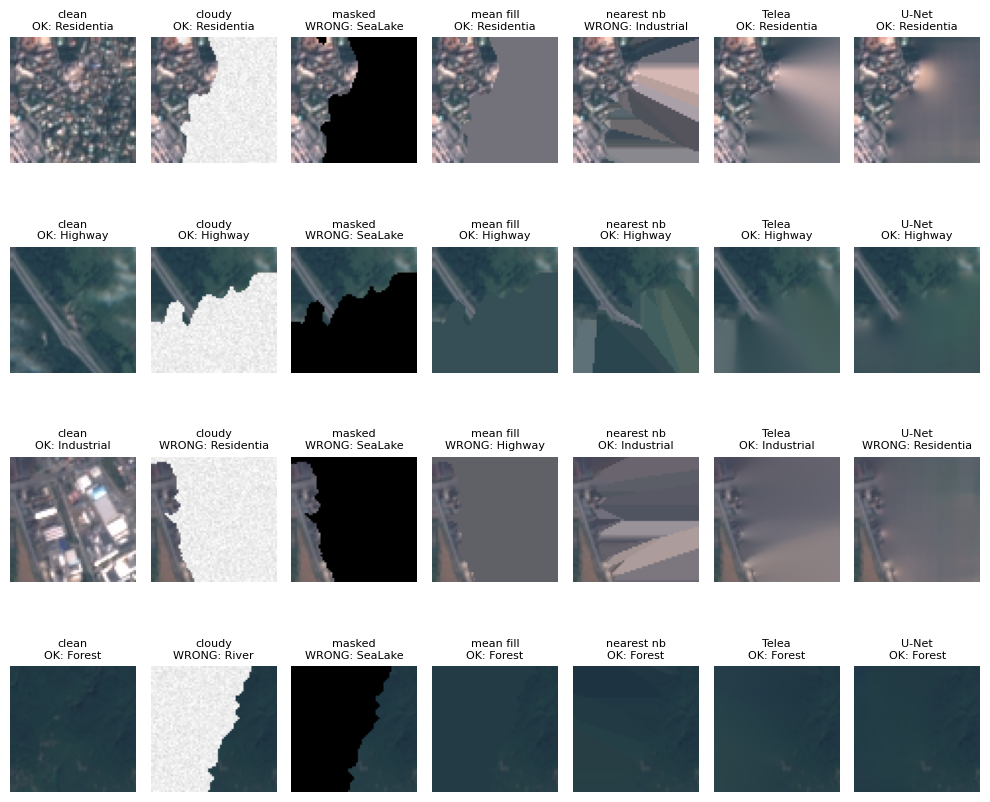

In [ ]:
# choose one test tile for each of four classes
pick = []
for c in ["Residential", "Highway", "Industrial", "Forest"]:
    ii = np.where(test_df["class_name"].values == c)[0]
    if len(ii): pick.append(int(ii[0]))
# the panels we show, left to right
names = ["clean", "cloudy", "masked", "mean fill", "nearest nb", "Telea", "U-Net"]
# one row per tile, one column per image
fig, axes = plt.subplots(len(pick), 7, figsize=(10, 2.2 * len(pick)))
axes = np.atleast_2d(axes)
for r, idx in enumerate(pick):
    # same seeds as the experiments
    rng = np.random.default_rng(42 + idx * 10 + 2)
    m = sim.generate_cloud_mask(BINS["60-80%"], rng=rng); cl = apply_thick(X[idx], m, rng)
    un = net_fill(unet, cl[None], m[None])[0]
    imgs = [X[idx], cl, masked_input(cl, m, 0), mean_fill(cl, m), nearest_neighbor_fill(cl, m), telea_inpaint(cl, m), un]
    for c_, (nm, im) in enumerate(zip(names, imgs)):
        p = int(predict(clf["fill_aware"], im[None])[0])
        ax = axes[r, c_]; ax.imshow(im); ax.axis("off")
        ax.set_title(f"{nm}\n{'OK' if p == y[idx] else 'WRONG'}: {CLASSES[p][:10]}", fontsize=8)
plt.tight_layout(); plt.show()

## 11. Summary: reproduced numbers vs the report

Each row compares one number in the report with the value this notebook computes. Small differences come from the saved checkpoints and rounding.

In [ ]:
# show the comparison table
display(pd.DataFrame(SUMMARY, columns=["claim", "report", "this notebook"]))

,claim,report,this notebook
0,"Fill-aware Telea minus masked, 10-30%",+5.2,+5.2
1,"Fill-aware Telea minus masked, 30-60%",+8.3,+8.3
2,"Fill-aware Telea minus masked, 60-80%",+13.2,+13.2
3,Telea vs U-Net at 60-80% (fill-aware),0.830 vs 0.826,0.830 vs 0.826
4,Pooled rho vs harmful flips: Whole-tile SSIM,-0.21,-0.21
5,Pooled rho vs harmful flips: Full-tile LPIPS,+0.22,+0.22
6,Pooled rho vs harmful flips: In-mask PSNR,-0.12,-0.13
7,Pooled rho vs harmful flips: In-mask SSIM,-0.09,-0.10
8,"Harmful flips, Telea 60-80% / mean fill 60-80%",13.9 / 17.9,12.1 / 17.0
9,Opacity crossover alpha,~0.65 (sampled points; interpolated value shown),0.67


**Notes.** Clouds are synthetic and white on 64×64 RGB EuroSAT tiles, so the results apply to this setting only. Live parts run inference with the saved weights: Table I (live), Table II, Tables IV–VI and the transfer check. Stored parts read the outputs of the training and RICE evaluation runs: Table I (3-seed), Table III, the taxonomy and Table VII.